# Sales Prediction Using Python

## Objective
To predict product sales based on advertising expenditure across TV, Radio, and Newspaper channels using machine learning regression models.

## Dataset
The Advertising dataset contains advertising expenditure for different media channels and the corresponding sales values.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Data Inspection

The dataset was inspected to understand its structure, dimensions, column names, and data types. The `head()` function displays the first five records, while `shape` provides the number of rows and columns. The `info()` function provides information about data types and non-null values.

This initial inspection helps verify that the dataset has been loaded correctly and identifies any data quality issues that need to be addressed before analysis.

In [3]:
df = pd.read_csv("Advertising.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (200, 4)


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [4]:
df.shape

(200, 4)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


## 4. Missing Values and Duplicate Check

The dataset was examined for missing values and duplicate records. Missing values can affect the accuracy of statistical analysis and machine learning models, while duplicate records may introduce unnecessary repetition.

The `isnull().sum()` function was used to count missing values in each column, and `duplicated().sum()` was used to identify duplicate rows.

The results were reviewed before proceeding with data cleaning. The standard Advertising dataset is expected to have no missing values or duplicate rows.

In [6]:
df.isnull().sum()

TV           0
radio        0
newspaper    0
sales        0
dtype: int64

In [7]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## 6. Descriptive Statistical Analysis

Descriptive statistics were calculated to summarize the numerical features of the dataset. The analysis includes count, mean, standard deviation, minimum, maximum, median, and quartiles.

The mean represents the average value, while the standard deviation measures the variation in the data. The minimum and maximum show the range of values, and the quartiles describe how the observations are distributed.

These statistics provide an initial understanding of advertising expenditure and sales before visualization and model development.

In [8]:
# Display statistical summary
df.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


## 7. Pair Plot Analysis

A pair plot was created to visualize the distributions of all numerical features and the relationships between every pair of variables.

The diagonal plots show the individual distributions of TV, Radio, Newspaper, and Sales. The remaining plots show pairwise relationships between these variables.

The pair plot helps identify possible trends, associations, and unusual observations. In particular, the relationships between each advertising channel and Sales provide an initial indication of which features may be useful for predicting sales.

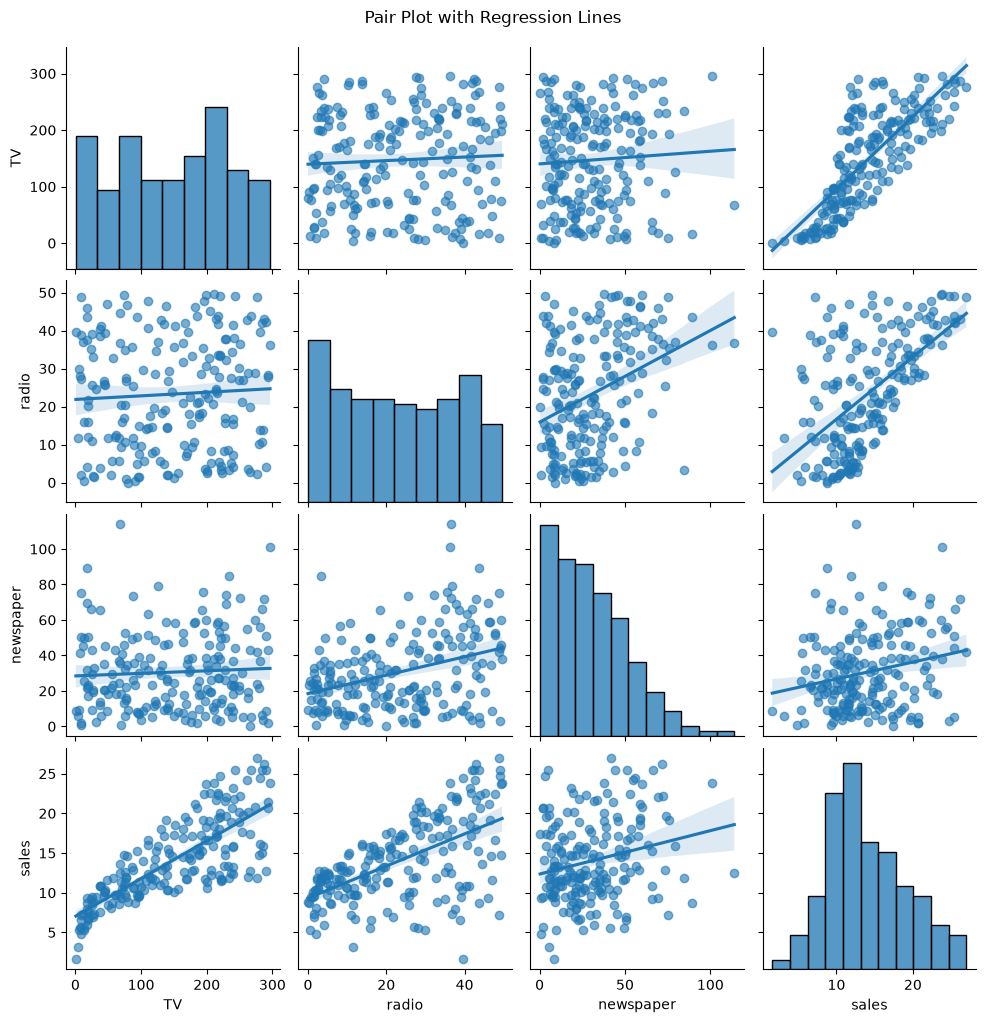

In [9]:
sns.pairplot(
    df,
    kind="reg",
    diag_kind="hist",
    plot_kws={"scatter_kws": {"alpha": 0.6}}
)

plt.suptitle("Pair Plot with Regression Lines", y=1.02)
plt.show()

## 8. Scatter Plot Analysis

Individual scatter plots were created to examine the relationships between Sales and each advertising channel: TV, Radio, and Newspaper.

- **Sales vs. TV:** Examines how sales vary with television advertising expenditure.
- **Sales vs. Radio:** Examines how sales vary with radio advertising expenditure.
- **Sales vs. Newspaper:** Examines how sales vary with newspaper advertising expenditure.

Trend lines were added to make the overall relationships easier to observe. The scatter plots help identify whether relationships appear positive, negative, weak, or approximately linear.

These visualizations support feature interpretation and help guide the regression analysis.

In [10]:
# Standardize column names correctly
df.columns = df.columns.str.strip().str.lower()

df.rename(columns={
    "tv": "TV",
    "radio": "Radio",
    "newspaper": "Newspaper",
    "sales": "Sales"
}, inplace=True)

print("Corrected columns:", df.columns.tolist())

Corrected columns: ['TV', 'Radio', 'Newspaper', 'Sales']


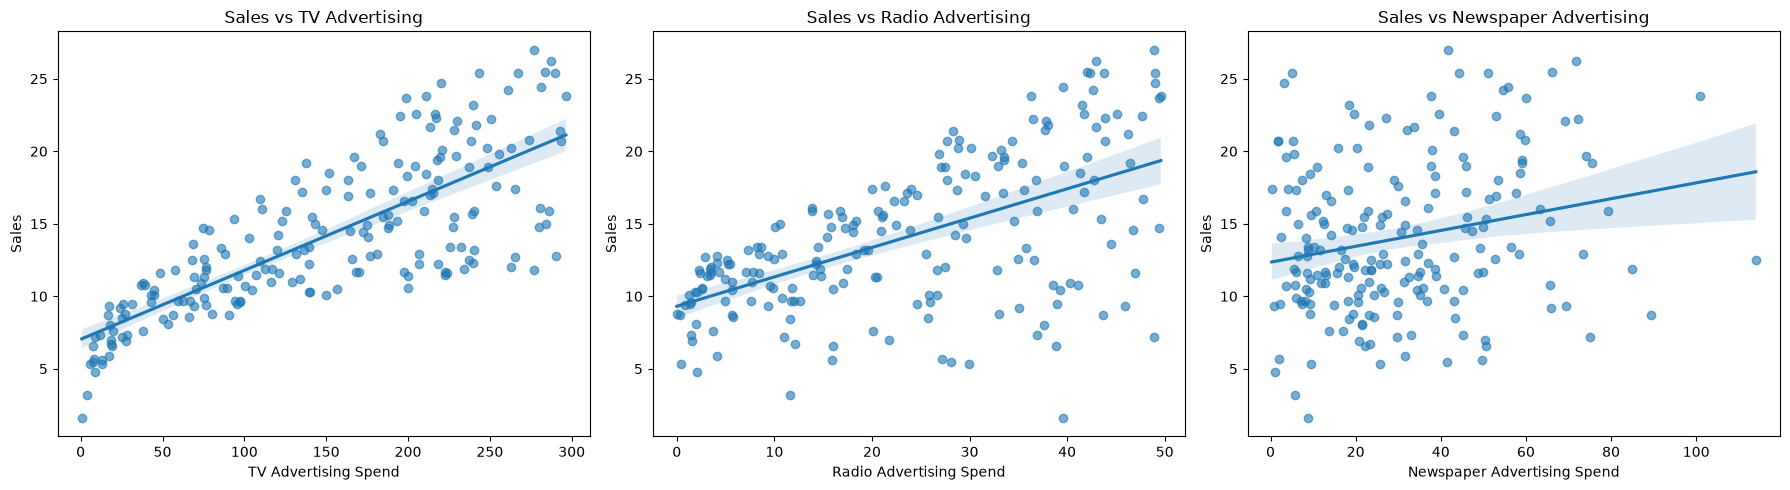

In [11]:
# Individual scatter plots: Sales vs advertising channels
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

channels = ["TV", "Radio", "Newspaper"]

for ax, channel in zip(axes, channels):
    sns.regplot(
        data=df,
        x=channel,
        y="Sales",
        ax=ax,
        scatter_kws={"alpha": 0.6}
    )

    ax.set_title(f"Sales vs {channel} Advertising")
    ax.set_xlabel(f"{channel} Advertising Spend")
    ax.set_ylabel("Sales")

plt.tight_layout()
plt.show()

## 9. Correlation Matrix Heatmap

A correlation matrix heatmap was generated to examine the strength and direction of linear relationships among TV, Radio, Newspaper, and Sales.

Correlation coefficients range from -1 to +1. A positive value indicates that two variables tend to increase together, while a negative value indicates that one tends to decrease as the other increases. Values close to zero indicate a weak linear relationship.

The heatmap helps compare the association of each advertising channel with Sales. However, correlation does not establish causation and does not, by itself, measure a feature's predictive importance.

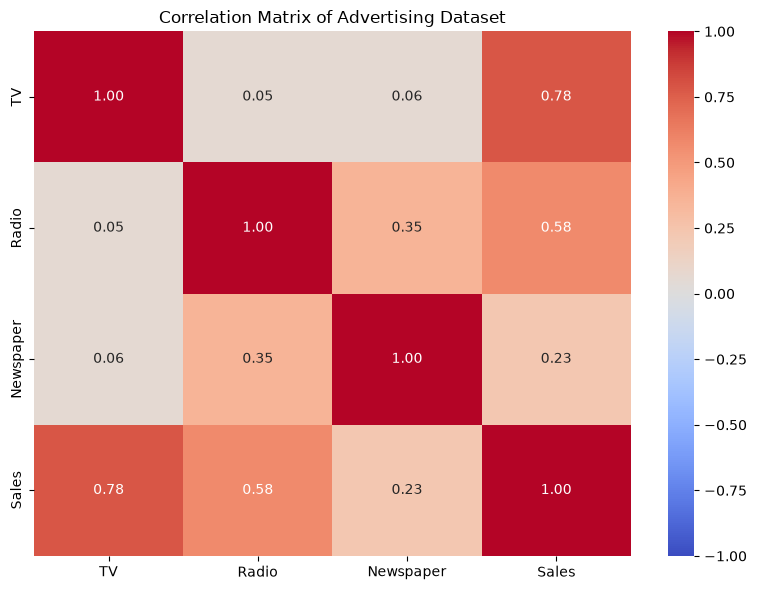

In [12]:
# Calculate the correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Advertising Dataset")
plt.tight_layout()
plt.show()

## Train/Test Split

The dataset was divided into training and testing sets using an 80:20 ratio. The training set contains 80% of the observations and is used to train the machine learning models. The testing set contains the remaining 20% and is used to evaluate predictions on unseen data.

The input features are TV, Radio, and Newspaper advertising expenditure, while Sales is the target variable. A fixed random state ensures reproducibility of the split.

In [13]:
from sklearn.model_selection import train_test_split

# Define input features and target
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Train/test split completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Train/test split completed successfully!
Training samples: 160
Testing samples: 40


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Model 2: Random Forest Regressor
random_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
random_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


## Model Evaluation Using MAE, RMSE, and R² Score

The performance of Linear Regression and Random Forest Regressor was evaluated using three regression metrics.

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted sales.
- **Root Mean Squared Error (RMSE):** Measures the square root of the average squared prediction errors and gives greater weight to larger errors.
- **R² Score:** Measures how much variation in the target variable is explained by the model on the test dataset.

MAE and RMSE are better when their values are lower, while a higher R² score generally indicates better predictive performance. The results were compared to identify the model that performed better on unseen data.

In [15]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Generate predictions
linear_predictions = linear_model.predict(X_test)
random_predictions = random_model.predict(X_test)

# Calculate evaluation metrics
results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_test, linear_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, linear_predictions)),
        "R2 Score": r2_score(y_test, linear_predictions)
    },
    {
        "Model": "Random Forest Regressor",
        "MAE": mean_absolute_error(y_test, random_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, random_predictions)),
        "R2 Score": r2_score(y_test, random_predictions)
    }
])

display(results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.4608,1.7816,0.8994
1,Random Forest Regressor,0.6296,0.7574,0.9818


In [16]:

# Select the best-performing model
best_model_name = results.sort_values(
    by=["R2 Score", "RMSE"],
    ascending=[False, True]
).iloc[0]["Model"]

if best_model_name == "Linear Regression":
    best_model = linear_model
else:
    best_model = random_model

# Generate predictions using the selected model
best_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("Best model selected successfully!")


Best Model: Random Forest Regressor
Best model selected successfully!


## Residual Plot Analysis

A residual plot was created to evaluate the prediction errors of the best-performing regression model. Residuals were calculated as the difference between actual sales and predicted sales.

The horizontal red dashed line represents zero error.

- **Random distribution:** If the residuals are scattered randomly around zero without a clear pattern, the model may have captured the main relationships in the data reasonably well.
- **Systematic distribution:** If the residuals form a curve, show a funnel shape, or follow another visible pattern, the model may be missing important relationships or have non-constant error variance.

The residual plot was examined alongside MAE, RMSE, and R² to assess the model's predictive performance.

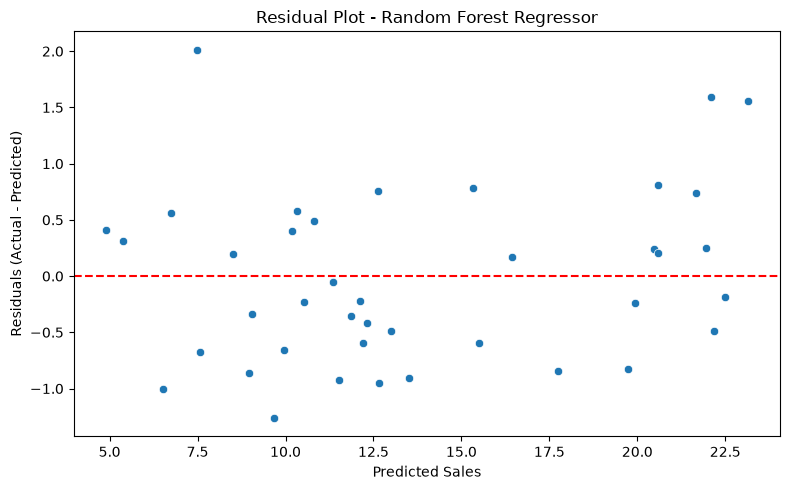

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
residuals = y_test - best_predictions

# Plot residuals
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=best_predictions,
    y=residuals
)

plt.axhline(y=0, color="red", linestyle="--")
plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

## Residual Plot Interpretation

Residuals represent the difference between actual sales and predicted sales. A residual plot helps evaluate whether the model's errors are randomly distributed around zero or show a systematic pattern.

- If residuals are randomly scattered around zero, the model may be capturing the relationships in the data reasonably well.
- If residuals show a curve, trend, or changing spread, the model may have systematic errors or may not capture some relationships adequately.

The final interpretation should be based on the residual plot generated by the notebook.

## Advertising Channel Impact Analysis

Feature analysis was performed to compare the predictive contribution of TV, Radio, and Newspaper advertising expenditure.

For Linear Regression, coefficients indicate the direction and estimated magnitude of the relationship between each advertising channel and predicted sales, holding the other features constant. For Random Forest, feature importance values indicate the relative contribution of each feature to the model's predictions.

The results were used to identify the most influential advertising channel according to the selected model. These findings describe predictive relationships and do not prove that an advertising channel causes higher sales.

Advertising Channel Importance:


,Feature Importance
TV,0.624844
Radio,0.362212
Newspaper,0.012944


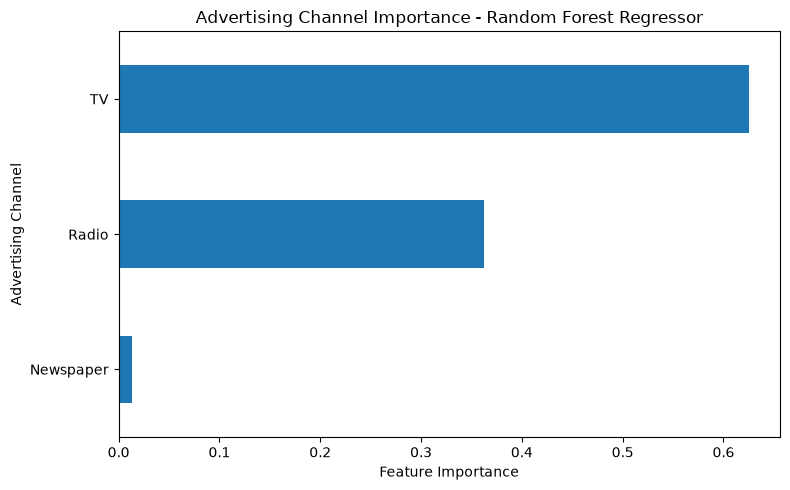

In [18]:
# Advertising Channel Importance

if best_model_name == "Linear Regression":
    importance = pd.Series(
        best_model.coef_,
        index=X.columns
    )
    importance_label = "Regression Coefficient"

else:
    importance = pd.Series(
        best_model.feature_importances_,
        index=X.columns
    )
    importance_label = "Feature Importance"

# Display importance values
print("Advertising Channel Importance:")
display(
    importance.to_frame(name=importance_label)
    .sort_values(by=importance_label, key=abs, ascending=False)
)

# Plot feature importance
importance.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title(f"Advertising Channel Importance - {best_model_name}")
plt.xlabel(importance_label)
plt.ylabel("Advertising Channel")
plt.tight_layout()
plt.show()

## Advertising Channel Impact Interpretation

The feature-importance analysis compares the contribution of TV, Radio, and Newspaper advertising expenditure to the model's predictions.

The channel with the highest feature-importance value is the most influential feature according to the selected Random Forest model. This indicates predictive importance, not necessarily a causal effect on sales.

The final conclusion should identify the channel with the highest value in the generated feature-importance results.

## Actual vs. Predicted Sales

The actual-versus-predicted plot compares observed sales values with the values estimated by the selected model. The diagonal reference line represents perfect predictions.

Points close to the diagonal indicate more accurate predictions, while points farther away indicate larger prediction errors. This visualization complements MAE, RMSE, and R² by providing a visual assessment of model accuracy.

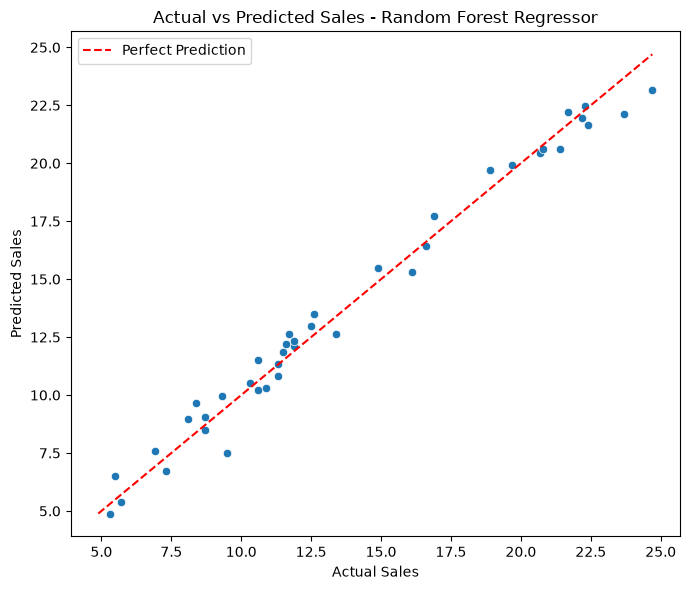

In [19]:
# Actual vs Predicted Sales

plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions
)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.title(f"Actual vs Predicted Sales - {best_model_name}")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.legend()
plt.tight_layout()
plt.show()

## Sales Prediction on New Data

The selected model was used to estimate sales for a new example containing TV, Radio, and Newspaper advertising expenditure. The input features were supplied in the same format used during model training.

The predicted value demonstrates how a trained regression model can estimate sales for new inputs. It is an estimate based on the patterns learned from the dataset and is not a guaranteed sales outcome.

In [20]:
# Predict sales for a new advertising example

new_advertising = pd.DataFrame({
    "TV": [150],
    "Radio": [25],
    "Newspaper": [20]
})

predicted_sales = best_model.predict(new_advertising)

print(f"Predicted sales: {predicted_sales[0]:.2f}")

Predicted sales: 15.17


# Conclusion

This project developed a machine learning solution to predict product sales based on advertising expenditure across TV, Radio, and Newspaper channels.

The dataset was inspected and analyzed using descriptive statistics, pair plots, scatter plots, and a correlation heatmap. Linear Regression and Random Forest Regressor were trained using an 80:20 train/test split.

The models were evaluated using MAE, RMSE, and R² score. The best-performing model was selected based on test-set performance. Residual analysis was used to examine prediction errors, while feature importance analysis helped identify which advertising channels were most useful for prediction.

Finally, the selected model was used to estimate sales for a new advertising example. The project provided practical experience in data analysis, visualization, regression modeling, and machine learning evaluation.

The results describe relationships in the available dataset and should not be interpreted as proof of causation.